## Importing Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import numpy as np

In [ ]:
sns.set(style="whitegrid")

## Load datasets

In [ ]:
# Load dataset safely
file_path = "data/DiseaseAndSymptoms.csv"
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)

In [ ]:
# Preview
print("Initial shape:", df.shape)
df = df.dropna(how="all")  # Drop fully empty rows

Initial shape: (4920, 18)


In [ ]:
# Strip column names and clean whitespace
df.columns = [col.strip() for col in df.columns]

In [ ]:
# Fill missing values with empty strings for symptom columns
symptom_cols = [col for col in df.columns if col.startswith("Symptom")]
df[symptom_cols] = df[symptom_cols].fillna("").applymap(lambda x: str(x).strip().lower())

C:\Users\ayush\AppData\Local\Temp\ipykernel_17256\4253762772.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df[symptom_cols] = df[symptom_cols].fillna("").applymap(lambda x: str(x).strip().lower())


In [ ]:
# Drop duplicates
df = df.drop_duplicates()
print("Cleaned shape:", df.shape)

Cleaned shape: (304, 18)


In [ ]:
# Count number of symptoms per disease
df["Symptom_Count"] = df[symptom_cols].apply(lambda row: sum(bool(x.strip()) for x in row), axis=1)

C:\Users\ayush\AppData\Local\Temp\ipykernel_17256\153584499.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_diseases.index, y=top_diseases.values, palette='magma')


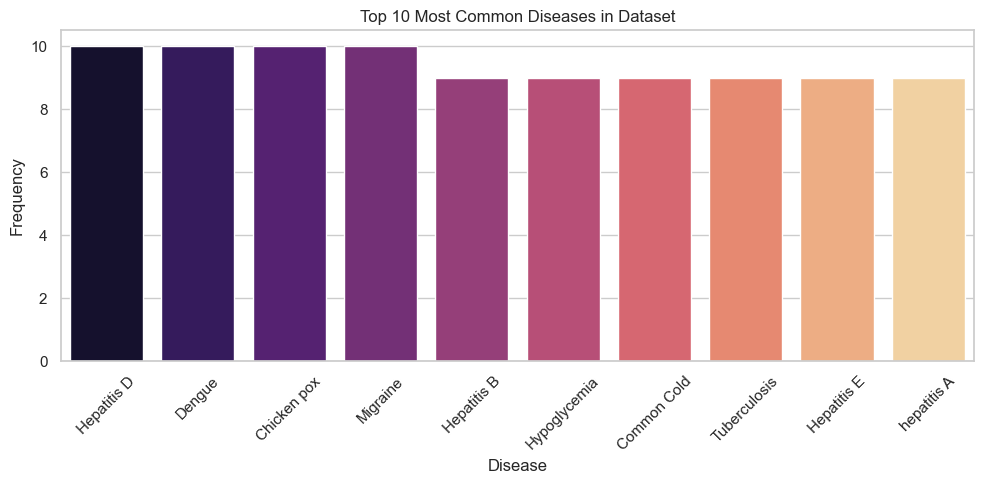

In [ ]:
# 1. Top 10 most frequent diseases
top_diseases = df['Disease'].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_diseases.index, y=top_diseases.values, palette='magma')
plt.title("Top 10 Most Common Diseases in Dataset")
plt.xticks(rotation=45)
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

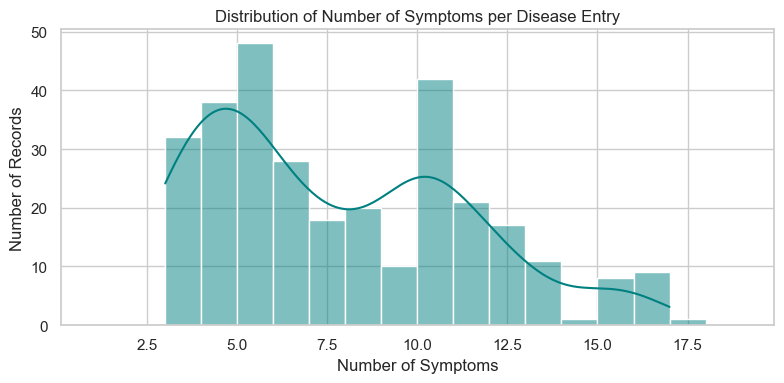

In [ ]:
# 2. Distribution of number of symptoms
plt.figure(figsize=(8, 4))
sns.histplot(df["Symptom_Count"], bins=range(1, 20), kde=True, color='teal')
plt.title("Distribution of Number of Symptoms per Disease Entry")
plt.xlabel("Number of Symptoms")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

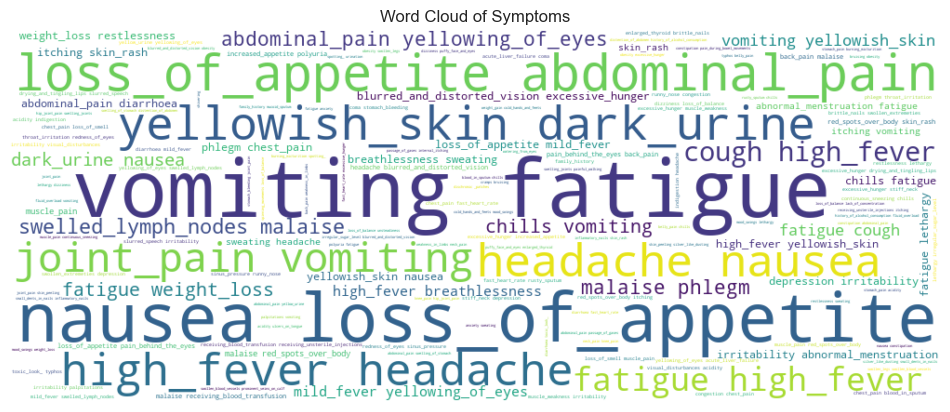

In [ ]:
# 3. Word Cloud of all symptoms
all_symptoms = df[symptom_cols].values.flatten()
all_symptoms = " ".join([symptom for symptom in all_symptoms if symptom and symptom != 'nan'])

wordcloud = WordCloud(width=1000, height=400, background_color='white').generate(all_symptoms)
plt.figure(figsize=(12, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Symptoms")
plt.show()

In [ ]:
# 4. Heatmap: Disease vs Most Common Symptoms
from collections import Counter

In [ ]:
# Flatten symptom list
symptom_counts = Counter([symptom for row in df[symptom_cols].values for symptom in row if symptom])
top_symptoms = [s for s, _ in symptom_counts.most_common(20)]

In [ ]:
# Create binary matrix: Disease x Top Symptoms
disease_symptom_matrix = pd.DataFrame(0, index=df['Disease'].unique(), columns=top_symptoms)
for _, row in df.iterrows():
    disease = row['Disease']
    for symptom in top_symptoms:
        if symptom in row[symptom_cols].values:
            disease_symptom_matrix.loc[disease, symptom] += 1

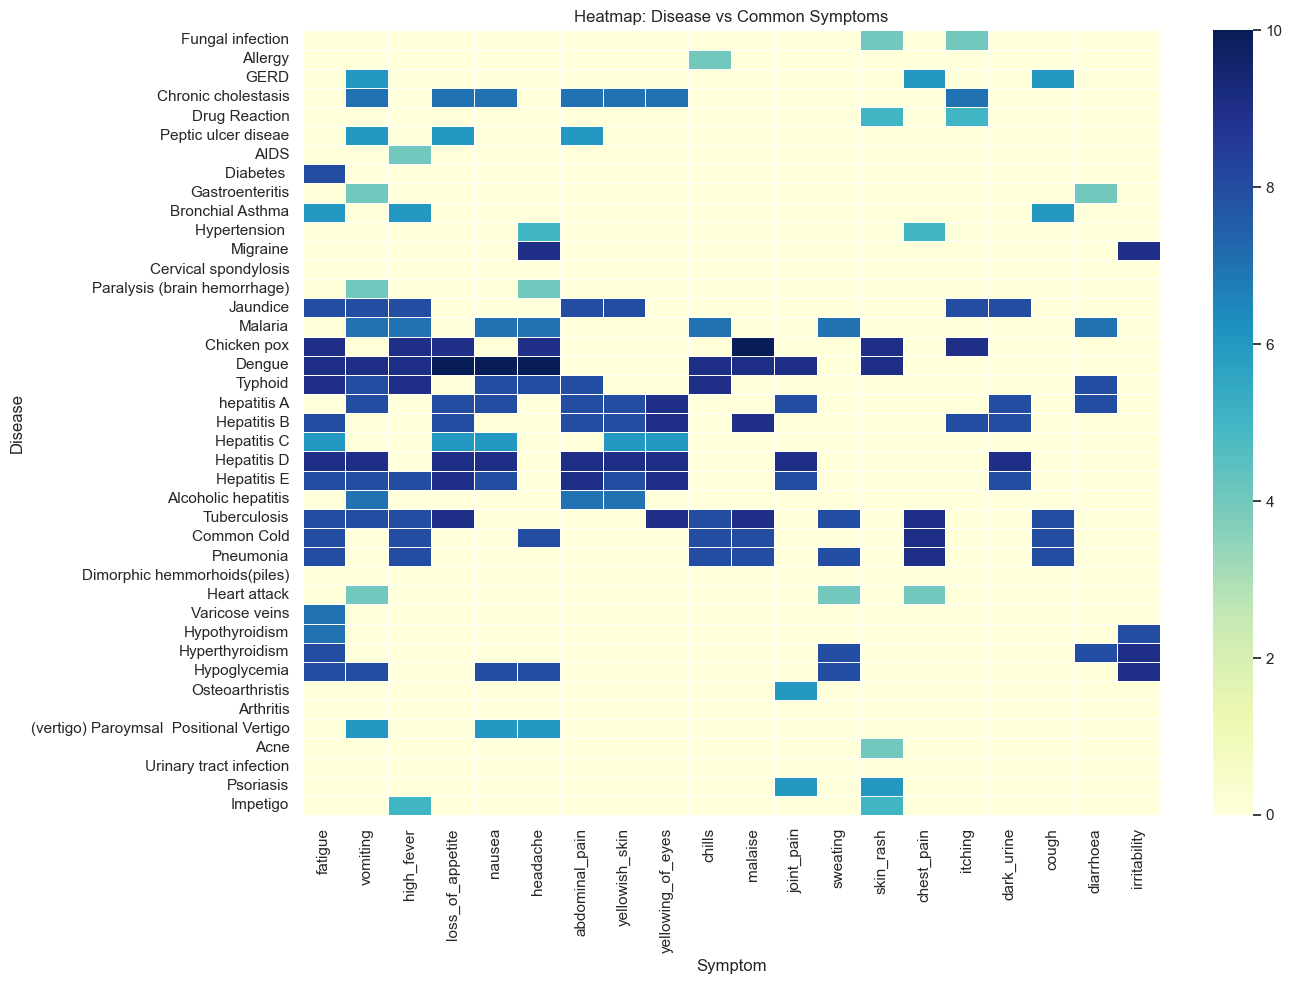

In [ ]:
# Heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(disease_symptom_matrix, cmap="YlGnBu", linewidths=0.5)
plt.title("Heatmap: Disease vs Common Symptoms")
plt.ylabel("Disease")
plt.xlabel("Symptom")
plt.tight_layout()
plt.show()

In [ ]:
df_cleaned = df[df["Symptom_Count"] >= 2].drop_duplicates()

# Step 6: Save cleaned data
df_cleaned.to_csv("data/cleaned_disease_symptoms.csv", index=False)
print("✅ Cleaned dataset saved to 'data/cleaned_disease_symptoms.csv'")

✅ Cleaned dataset saved to 'data/cleaned_disease_symptoms.csv'
